In [52]:
!pip install pandasql
from google.colab import files
files.upload()

import pandas as pd
from pandasql import sqldf

df = pd.read_csv("user_events.csv")
df.head()



Saving user_events.csv to user_events (1).csv


,event_id,user_id,event_type,event_date,product_id,amount,traffic_source
0,8490,5024,page_view,2025-12-30 04:58:24.517006,205,NaN,social
1,2296,1713,page_view,2025-12-30 05:10:26.276377,201,NaN,organic
2,3896,2558,page_view,2025-12-30 05:11:09.001887,404,NaN,organic
3,2297,1713,add_to_cart,2025-12-30 05:13:26.276377,201,NaN,organic
4,2298,1713,checkout_start,2025-12-30 05:16:26.276377,201,NaN,organic


In [53]:
pysqldf = lambda q: sqldf(q, globals())

pysqldf("SELECT * FROM df LIMIT 10")


,event_id,user_id,event_type,event_date,product_id,amount,traffic_source
0,8490,5024,page_view,2025-12-30 04:58:24.517006,205,NaN,social
1,2296,1713,page_view,2025-12-30 05:10:26.276377,201,NaN,organic
2,3896,2558,page_view,2025-12-30 05:11:09.001887,404,NaN,organic
3,2297,1713,add_to_cart,2025-12-30 05:13:26.276377,201,NaN,organic
4,2298,1713,checkout_start,2025-12-30 05:16:26.276377,201,NaN,organic
5,8438,4993,page_view,2025-12-30 05:20:55.416929,205,NaN,organic
6,2299,1713,payment_info,2025-12-30 05:23:26.276377,201,NaN,organic
7,2300,1713,purchase,2025-12-30 05:25:26.276377,201,48.3,organic
8,8649,5102,page_view,2025-12-30 05:25:27.600119,102,NaN,organic
9,3897,2558,add_to_cart,2025-12-30 05:29:09.001887,404,NaN,organic


In [54]:
pysqldf("""
    WITH funnel_stages AS (
        SELECT
            COUNT(DISTINCT CASE WHEN event_type = 'page_view'      THEN user_id END) AS stage_1_views,
            COUNT(DISTINCT CASE WHEN event_type = 'add_to_cart'    THEN user_id END) AS stage_2_cart,
            COUNT(DISTINCT CASE WHEN event_type = 'checkout_start' THEN user_id END) AS stage_3_checkout,
            COUNT(DISTINCT CASE WHEN event_type = 'payment_info'   THEN user_id END) AS stage_4_payment,
            COUNT(DISTINCT CASE WHEN event_type = 'purchase'       THEN user_id END) AS stage_5_purchase
        FROM df
        WHERE event_date >= (
            SELECT datetime(max(event_date), '-30 days') FROM df
        )
    )
    SELECT
    stage_1_views,
    stage_2_cart,
    ROUND(stage_2_cart * 100/stage_1_views) as view_to_cart,
    stage_3_checkout,
    ROUND(stage_3_checkout * 100/stage_2_cart) as cart_to_checkout,
    stage_4_payment,
    ROUND(stage_4_payment * 100/stage_3_checkout) as checkout_to_pay,
    stage_5_purchase,
    ROUND(stage_5_purchase * 100/stage_4_payment) as pay_to_purchase,
    ROUND(stage_5_purchase * 100/stage_1_views) as overall_funnel_rate


    FROM funnel_stages
""")

,stage_1_views,stage_2_cart,view_to_cart,stage_3_checkout,cart_to_checkout,stage_4_payment,checkout_to_pay,stage_5_purchase,pay_to_purchase,overall_funnel_rate
0,4268,1332,31.0,951,71.0,768,80.0,708,92.0,16.0


In [55]:
pysqldf("""
    WITH funnel_source AS (
        SELECT
            traffic_source,
            COUNT(DISTINCT CASE WHEN event_type = 'page_view'      THEN user_id END) AS views,
            COUNT(DISTINCT CASE WHEN event_type = 'add_to_cart'    THEN user_id END) AS cart,
            COUNT(DISTINCT CASE WHEN event_type = 'purchase'       THEN user_id END) AS purchase
        FROM df
        WHERE event_date >= (
            SELECT datetime(max(event_date), '-30 days') FROM df
        )
        GROUP BY traffic_source
    )
    SELECT
        traffic_source,
        views,
        cart,
        ROUND(cart * 100.0 / views)         AS conversion_cart,
        ROUND(purchase * 100.0 / views)     AS purchase_conversion,
        ROUND(purchase * 100.0 / cart)     AS cart_to_purchase_conversion
    FROM funnel_source
    ORDER BY views DESC
""")

,traffic_source,views,cart,conversion_cart,purchase_conversion,cart_to_purchase_conversion
0,organic,1750,576,33.0,17.0,52.0
1,social,1253,171,14.0,7.0,49.0
2,paid_ads,820,305,37.0,21.0,57.0
3,email,445,280,63.0,34.0,54.0


In [69]:
pysqldf("""
    WITH user_journey AS (
        SELECT
            user_id,
            MIN(CASE WHEN event_type = 'page_view'   THEN event_date END) AS view_time,
            MIN(CASE WHEN event_type = 'add_to_cart' THEN event_date END) AS cart_time,
            MIN(CASE WHEN event_type = 'purchase'    THEN event_date END) AS purchase_time
        FROM df
        WHERE event_date >= (
            SELECT datetime(max(event_date), '-30 days') FROM df
        )
        GROUP BY user_id
        HAVING MIN(CASE WHEN event_type = 'purchase' THEN event_date END) IS NOT NULL
    )
    SELECT
        COUNT(*) AS converted_users,
        ROUND(AVG((julianday(cart_time) - julianday(view_time)) * 24 * 60), 2) AS avg_view_to_cart_minutes,
        ROUND(AVG((julianday(purchase_time) - julianday(cart_time)) * 24 * 60), 2) AS avg_cart_to_purchase_minutes,
        ROUND(AVG((julianday(purchase_time) - julianday(view_time)) * 24 * 60), 2) AS avg_total_journey_minutes
    FROM user_journey
""")

,converted_users,avg_view_to_cart_minutes,avg_cart_to_purchase_minutes,avg_total_journey_minutes
0,708,11.19,13.36,24.55


In [78]:
pysqldf("""
    WITH funnel_revenue AS (
        SELECT
            COUNT(DISTINCT CASE WHEN event_type = 'page_view' THEN user_id END)   AS total_visitors,
            COUNT(DISTINCT CASE WHEN event_type = 'purchase'  THEN user_id END)   AS total_buyers,
            COUNT(CASE WHEN event_type = 'purchase' THEN 1 END)                   AS total_orders,
            ROUND(SUM(CASE WHEN event_type = 'purchase' THEN amount END), 2)      AS total_revenue
        FROM df
        WHERE event_date >= (
            SELECT datetime(max(event_date), '-30 days') FROM df
        )
    )
    SELECT
        total_visitors,
        total_buyers,
        total_orders,
        total_revenue,
        ROUND(total_revenue * 1.0 / total_orders, 2)         AS aov,
        ROUND(total_revenue * 1.0 / total_buyers, 2)         AS arpu,
        ROUND(100.0 * total_buyers / total_visitors, 2)      AS conversion_rate_pct,
        ROUND(1.0 * total_orders / total_buyers, 2)          AS orders_per_buyer
    FROM funnel_revenue
""")

,total_visitors,total_buyers,total_orders,total_revenue,aov,arpu,conversion_rate_pct,orders_per_buyer
0,4268,708,708,76037.93,107.4,107.4,16.59,1.0


<Figure size 640x480 with 0 Axes>

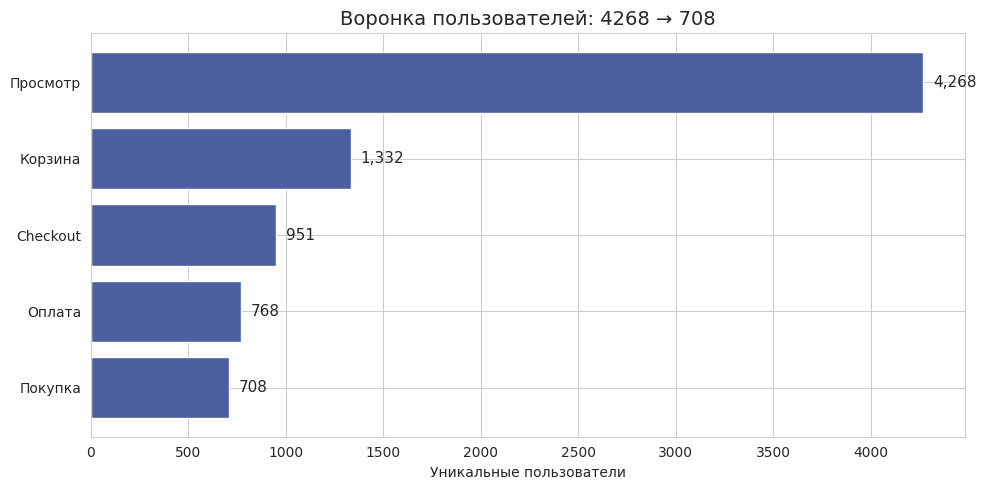

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs('reports/figures', exist_ok=True)

plt.savefig('reports/figures/04_journey_time.png', dpi=150)

sns.set_style("whitegrid")

funnel_data = pd.DataFrame({
    'stage': ['Просмотр', 'Корзина', 'Checkout', 'Оплата', 'Покупка'],
    'users': [4268, 1332, 951, 768, 708]
})

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(funnel_data['stage'], funnel_data['users'], color='#4C60A0')
for bar, val in zip(bars, funnel_data['users']):
    ax.text(val + 50, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=11)
ax.invert_yaxis()
ax.set_title('Воронка пользователей: 4268 → 708', fontsize=14)
ax.set_xlabel('Уникальные пользователи')
plt.tight_layout()
plt.savefig('reports/figures/01_funnel.png', dpi=150)
plt.show()

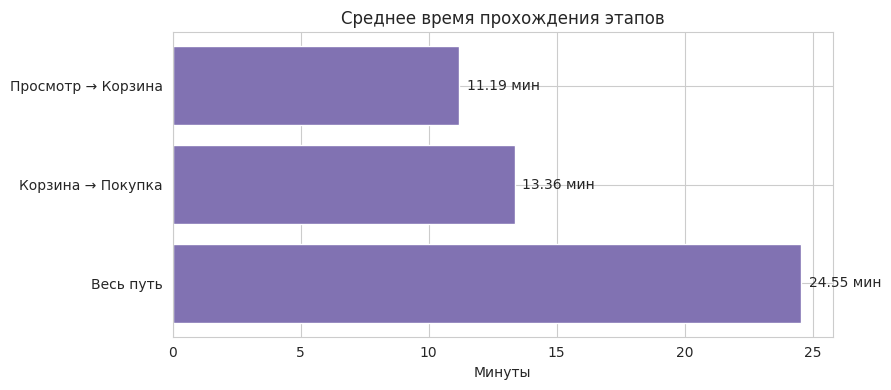

In [88]:
# 4. ВРЕМЯ ПУТИ — горизонтальные «этапы»
journey = pd.DataFrame({
    'stage': ['Просмотр → Корзина', 'Корзина → Покупка', 'Весь путь'],
    'minutes': [11.19, 13.36, 24.55]
})

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(journey['stage'], journey['minutes'], color='#8172B2')
for i, v in enumerate(journey['minutes']):
    ax.text(v + 0.3, i, f'{v} мин', va='center')
ax.invert_yaxis()
ax.set_title('Среднее время прохождения этапов')
ax.set_xlabel('Минуты')
plt.tight_layout()
plt.savefig('reports/figures/04_journey_time.png', dpi=150)
plt.show()